# Case Study 26 — Collections and SLA: Time Until an Event Happens

**Poisson arrivals and exponential waiting times · staffing with Erlang C · censored durations · Kaplan-Meier survival curves ·
log-rank test · Cox proportional hazards · parametric (Weibull) survival models · SLA breach probability · why naive averages of durations are wrong**

| | |
|---|---|
| **Domain** | Collections and operations |
| **Stakeholders** | Head of Collections, Operations Planning |
| **Difficulty** | Advanced |
| **Importance** | 🟢 LESS COMMON |
| **Builds on** | Case 01 (distributions), Case 11 (logistic regression, odds), Case 17 (missing data), Case 20 (stratification) |
| **Data** | 6,000 accounts followed until paid up (or censored); call arrivals per 15 minutes for 20 working days |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual customer data.
> See `src/generate_data.py`. A teaching-only answer key (true 30-day resolution probability and median time for every group) is opened only in Section 13.

**What you will learn**

1. When counts per interval are **Poisson**, and how to test it (dispersion), and why waiting times are **exponential**.
2. How to turn an arrival rate into a **staffing** number (Erlang C).
3. Why **censoring** makes ordinary means and percentages of durations wrong, and how **Kaplan-Meier** handles it.
4. How to compare groups (**log-rank**), adjust (**Cox**), and extrapolate (**Weibull**), and how to read an **SLA breach probability**.

## Section 1 — Business context

Collections has two questions in the same week.

> **Operations:** *"Calls to the collections desk spike mid-morning and mid-afternoon. How many agents do we need each hour so customers do not wait more than 20 seconds for 80% of calls?"*
>
> **Head of Collections:** *"Our SLA is that 70% of overdue accounts are paid up within 30 days. Last quarter's report says 'average time to resolve is 32 days, and 61% of resolved accounts were resolved within 30 days': close to the SLA. Does the call-first strategy actually speed things up, and are we really close?"*

## Section 2 — Business questions

1. How do call arrivals behave: Poisson or something else? How many agents are needed?
2. What fraction of accounts is really resolved within 30 days, given many are still open?
3. Do strategy, bucket and balance change the speed of resolution, and by how much?
4. Which segments miss the 70%-in-30-days SLA?
5. How far can we trust a model for the long tail (90 or 180 days)?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Arrivals and staffing | Are counts Poisson within an hour? Rate by hour; probability of exceeding capacity | Dispersion test, exact Poisson CIs, Erlang C |
| 2 | Share resolved by 30 days | Survival function with censoring | Kaplan-Meier with CI; naive alternatives |
| 3 | Group differences | Compare survival curves; hazard ratios | Log-rank test, Cox PH, parametric Weibull |
| 4 | SLA misses | P(resolved by 30 days) per segment | KM per segment, CI against 70% |
| 5 | Long tail | Extrapolation beyond the data | Weibull fit checked against KM |

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.optimize import minimize
import statsmodels.api as sm
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.duration.survfunc import survdiff
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "26_collections_sla_time_to_event"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
warnings.filterwarnings("ignore")
rng = rng_for_case(2626)
SLA_DAYS, SLA_TARGET = 30, 0.70
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

## Section 4 — Part A: call arrivals

720 intervals of 15 minutes over 20 working days; missing 0
All intervals pooled: mean 9.65, variance 19.31, variance/mean = 2.00  (a Poisson variable has variance = mean)


,mean,variance / mean,p-value (two-sided),rate 95% CI low,rate 95% CI high
hour,,,,,
9,5.6500,1.1296,0.4041,5.1411,6.1957
10,10.7125,1.1750,0.2740,10.0072,11.4544
11,14.1875,0.8228,0.2570,13.3740,15.0375
12,9.4875,1.0220,0.8492,8.8245,10.1872
13,4.7875,1.0243,0.8382,4.3200,5.2918
14,10.0375,0.9722,0.9018,9.3552,10.7564
15,13.8875,1.0537,0.7008,13.0828,14.7288
16,11.1500,0.8040,0.2044,10.4302,11.9064
17,6.9250,0.9936,0.9900,6.3603,7.5264


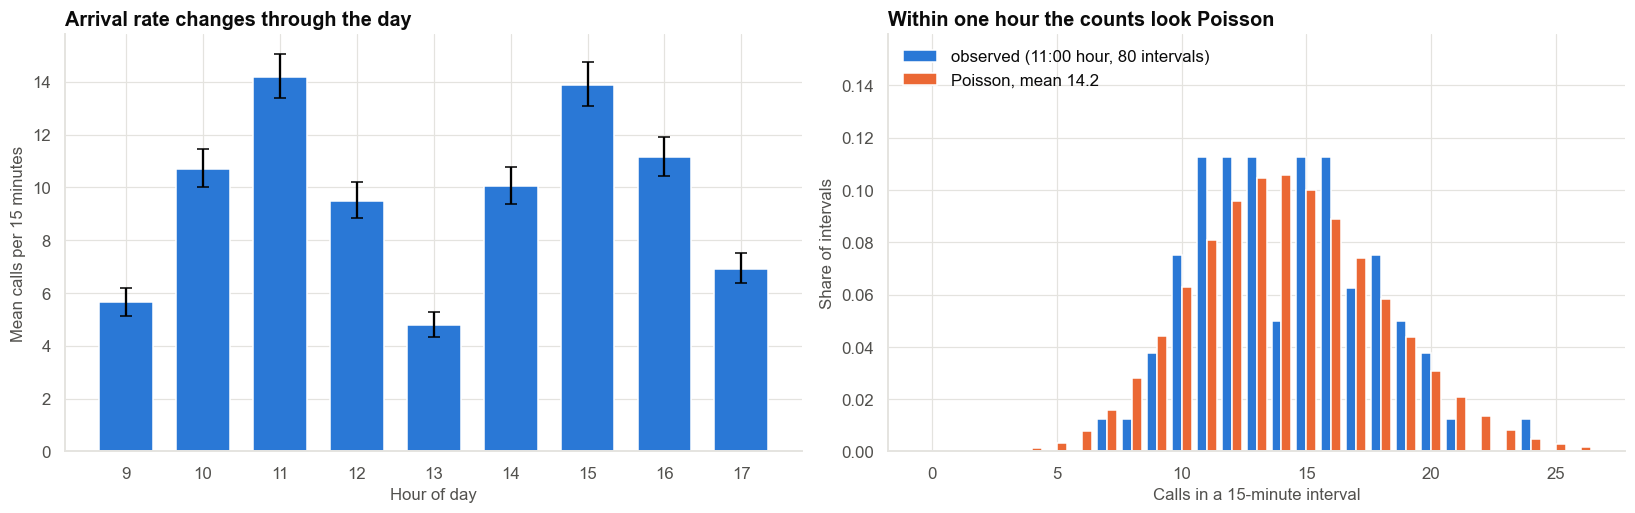

In [2]:
calls = pd.read_csv(PATHS["data"] / "call_arrivals.csv")
calls["hour"] = calls["interval_start"].str[:2].astype(int)
print(f"{len(calls)} intervals of 15 minutes over {calls['date'].nunique()} working days; missing {calls.isna().sum().sum()}")
m_, v_ = calls["calls"].mean(), calls["calls"].var(ddof=1)
print(f"All intervals pooled: mean {m_:.2f}, variance {v_:.2f}, variance/mean = {v_ / m_:.2f}  (a Poisson variable has variance = mean)")
by_h = calls.groupby("hour")["calls"].agg(["mean", "var", "count", "sum"])
by_h["variance / mean"] = by_h["var"] / by_h["mean"]
by_h["dispersion chi-square"] = (by_h["count"] - 1) * by_h["variance / mean"]
by_h["p-value (two-sided)"] = [2 * min(stats.chi2.cdf(c, n - 1), stats.chi2.sf(c, n - 1)) for c, n in zip(by_h["dispersion chi-square"], by_h["count"])]
ci = [stats.chi2.interval(0.95, 2 * s) for s in by_h["sum"]]
by_h["rate 95% CI low"] = [lo / 2 / n for (lo, hi), n in zip(ci, by_h["count"])]
by_h["rate 95% CI high"] = [stats.chi2.ppf(0.975, 2 * (s + 1)) / 2 / n for s, n in zip(by_h["sum"], by_h["count"])]
save_table(by_h[["mean", "variance / mean", "p-value (two-sided)", "rate 95% CI low", "rate 95% CI high"]], "arrivals_by_hour", PATHS["tables"])
display(by_h[["mean", "variance / mean", "p-value (two-sided)", "rate 95% CI low", "rate 95% CI high"]])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
ax.bar(by_h.index, by_h["mean"], color=PRIMARY, width=0.7, yerr=[by_h["mean"] - by_h["rate 95% CI low"], by_h["rate 95% CI high"] - by_h["mean"]], capsize=4)
ax.set_xticks(by_h.index); ax.set(xlabel="Hour of day", ylabel="Mean calls per 15 minutes", title="Arrival rate changes through the day")
ax = axes[1]
pk = calls[calls.hour == 11]["calls"]; ks = np.arange(0, pk.max() + 3)
ax.bar(ks - 0.2, [np.mean(pk == k) for k in ks], width=0.4, color=PRIMARY, label="observed (11:00 hour, 80 intervals)")
ax.bar(ks + 0.2, stats.poisson.pmf(ks, pk.mean()), width=0.4, color=COLORS["orange"], label=f"Poisson, mean {pk.mean():.1f}")
ax.set(xlabel="Calls in a 15-minute interval", ylabel="Share of intervals", title="Within one hour the counts look Poisson"); ax.set_ylim(0, ax.get_ylim()[1] * 1.35); ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); save_fig(fig, "fig01_arrivals", PATHS["figures"]); plt.show()

**Observation.** Pooled over the whole day, the 15-minute call counts have a mean of 9.65 and a variance of 19.3: **variance ÷ mean = 2.0**, far from the Poisson value of 1. But within each hour the ratio is 0.80 to 1.18 and no hour rejects the Poisson hypothesis (all p > 0.2).
The rate climbs from about 5.7 calls per 15 minutes at 09:00 to **14.2 at 11:00** and **13.9 at 15:00**, with lunch (12:00) and 13:00 quiet at 9.5 and 4.8; the 95% intervals for each hour are about ±0.7 calls.

**Interpretation.** Counts are Poisson **within a stable period**, but the rate itself changes through the day, so a single day-wide Poisson model is wrong (it gives overdispersion). The right model is a Poisson process with a time-varying rate: estimate a rate per period.
At the peak, the chance of more than 20 calls in one 15-minute interval is about 5%.

### 4.1 Waiting times and staffing

If calls arrive as a Poisson process with rate λ, the time **between** calls is **exponential** with mean 1/λ, memoryless (the time already waited says nothing about the time remaining).
To staff a desk we use the **Erlang C** model: c agents, calls arriving at rate λ per minute, average handling time (AHT) 1/μ. It gives the probability that a call has to wait, and
P(wait > t) = P(wait) × exp(−(c·μ − λ) t). We assume AHT = 6 minutes and a service target of 80% of calls answered within 20 seconds.

In [3]:
def erlang_c(c, a):
    # probability that an arriving call must wait; a = offered load in erlangs
    if c <= a: return 1.0
    s = sum(a ** k / np.math.factorial(k) for k in range(c)) if hasattr(np, "math") else sum(a ** k / __import__("math").factorial(k) for k in range(c))
    top = a ** c / __import__("math").factorial(c) * c / (c - a)
    return top / (s + top)
def service_level(c, lam_per_min, aht_min, t_min):
    a = lam_per_min * aht_min; pw = erlang_c(c, a)
    return 1 - pw * np.exp(-(c - a) / aht_min * t_min) if c > a else 0.0
AHT, T20 = 6.0, 20 / 60
rows = []
for h, r in by_h.iterrows():
    lam = r["mean"] / 15
    c_need = next(c for c in range(1, 80) if service_level(c, lam, AHT, T20) >= 0.80)
    rows.append({"hour": h, "calls per 15 min": r["mean"], "calls per minute": lam, "offered load (erlangs)": lam * AHT, "agents needed (80/20)": c_need,
                 "service level at that staffing": service_level(c_need, lam, AHT, T20), "service level with one fewer agent": service_level(c_need - 1, lam, AHT, T20)})
staff = pd.DataFrame(rows).set_index("hour")
save_table(staff, "staffing_erlang_c", PATHS["tables"]); display(staff)
lam_pk = by_h.loc[11, "mean"]
print(f"Peak hour: mean {lam_pk:.1f} calls per 15 minutes. P(more than 20 calls in one 15-minute interval) = {stats.poisson.sf(20, lam_pk):.3f};  P(no call in the next minute) = {np.exp(-lam_pk / 15):.2f}")
avg_staff = int(round((by_h["mean"].mean() / 15) * AHT)) + 1
fixed_sl = [service_level(avg_staff, r['mean'] / 15, AHT, T20) for _, r in by_h.iterrows()]
print(f"A flat roster of {avg_staff} agents all day would give service levels of {min(fixed_sl):.0%} (worst hour) to {max(fixed_sl):.0%} (best hour)")

,calls per 15 min,calls per minute,offered load (erlangs),agents needed (80/20),service level at that staffing,service level with one fewer agent
hour,,,,,,
9,5.6500,0.3767,2.2600,5,0.9208,0.7784
10,10.7125,0.7142,4.2850,7,0.8461,0.6735
11,14.1875,0.9458,5.6750,9,0.8745,0.7489
12,9.4875,0.6325,3.7950,7,0.9094,0.7902
13,4.7875,0.3192,1.9150,4,0.8631,0.6184
14,10.0375,0.6692,4.0150,7,0.8837,0.7417
15,13.8875,0.9258,5.5550,9,0.8875,0.7715
16,11.1500,0.7433,4.4600,7,0.8179,0.6240
17,6.9250,0.4617,2.7700,5,0.8383,0.6105


Peak hour: mean 14.2 calls per 15 minutes. P(more than 20 calls in one 15-minute interval) = 0.053;  P(no call in the next minute) = 0.39
A flat roster of 5 agents all day would give service levels of 0% (worst hour) to 96% (best hour)


**Observation.** Using Erlang C (average handling time 6 minutes, target 80% of calls answered within 20 seconds), the desk needs **4 agents** at 13:00, 5 at 09:00 and 17:00, **7** at 10:00, 12:00, 14:00 and 16:00, and **9** at 11:00 and 15:00. Offered load at the peak is 5.7 erlangs; the chance that a caller sees no new call in the next minute is 39%.
A flat roster of 5 agents all day is overloaded at the peaks (offered load above the number of agents) and over-staffed in the quiet hours.

**Interpretation.** Staffing is driven by the **hourly rate**, not the daily average. The minimum number of agents is always above the offered load in erlangs, because queues build faster than they drain when arrivals are random: running at 95% utilisation gives long waits.
Assumptions to check: Poisson arrivals (supported within the hour), exponential handling times (not tested here; real handling times are often more skewed), and no abandoned calls.

## Section 5 — Part B: time until an account is paid up

### 5.1 The data

In [4]:
acc = pd.read_csv(PATHS["data"] / "collections_accounts.csv", parse_dates=["entry_date"])
print(f"{len(acc):,} accounts; entry dates {acc.entry_date.min():%b %Y} to {acc.entry_date.max():%b %Y}; missing {acc.isna().sum().sum()}")
print(f"Resolved (paid up): {acc.resolved.mean():.1%};  censored (still open or transferred): {1 - acc.resolved.mean():.1%};  longest follow-up {acc.duration_days.max()} days")
cens = acc[acc.resolved == 0]["duration_days"]
print(f"Censored accounts' follow-up: median {cens.median():.0f} days;  {np.mean(cens >= 90):.0%} of censored are at 90+ days")
display(acc.head())
display(acc.groupby(["strategy", "bucket"]).agg(accounts=("resolved", "size"), resolved=("resolved", "mean"), median_followup=("duration_days", "median")))

6,000 accounts; entry dates Jan 2023 to Jun 2024; missing 0
Resolved (paid up): 64.7%;  censored (still open or transferred): 35.3%;  longest follow-up 120 days
Censored accounts' follow-up: median 51 days;  33% of censored are at 90+ days


,account_id,entry_date,strategy,bucket,balance_band,duration_days,resolved
0,AC26100000,2024-04-24,sms_first,late,mid,36,1
1,AC26100001,2023-11-02,call_first,early,mid,120,0
2,AC26100002,2023-02-15,call_first,early,high,1,1
3,AC26100003,2024-01-13,sms_first,late,mid,73,1
4,AC26100004,2024-06-22,sms_first,early,mid,49,1


accounts  resolved  median_followup
strategy   bucket                                     
call_first early       1778    0.7525          22.0000
           late        1203    0.6318          32.0000
sms_first  early       1779    0.6431          29.0000
           late        1240    0.5145          45.5000

**What is censoring?** For a censored account we know only that it had **not** been paid up by the end of its follow-up, not when (or whether) it will be.
Ignoring censoring in either of the two obvious ways biases the answer:

- **Averaging the observed durations** treats an account still open at 90 days as if it resolved at day 90.
- **Dropping the unresolved accounts** keeps only the quickest cases.

### 5.2 What the last quarterly report computed

In [5]:
res = acc[acc.resolved == 1]
naive_mean_resolved = res.duration_days.mean()
naive_share_resolved = (res.duration_days <= SLA_DAYS).mean()
naive_share_all = ((acc.resolved == 1) & (acc.duration_days <= SLA_DAYS)).mean()
naive_mean_all = acc.duration_days.mean()
naive = pd.DataFrame({"value": [naive_mean_resolved, naive_share_resolved, naive_mean_all, naive_share_all]},
                     index=["mean days, resolved accounts only (report)", "share of RESOLVED accounts paid by day 30 (report)", "mean days, all accounts (censored treated as events)",
                            "share of ALL accounts known paid by day 30 (censored treated as unresolved)"])
save_table(naive, "naive_summaries", PATHS["tables"]); display(naive)

,value
"mean days, resolved accounts only (report)",31.5936
share of RESOLVED accounts paid by day 30 (report),0.6059
"mean days, all accounts (censored treated as events)",41.9622
share of ALL accounts known paid by day 30 (censored treated as unresolved),0.3918


**Observation.** Of 6,000 accounts, **65% were paid up and 35% were still open or transferred (censored)**. A third of the censored accounts have 90 or more days of follow-up, i.e. they are slow cases, not missing data.
The quarterly report's statistics: the mean days among resolved accounts is **31.6**, and **61%** of resolved accounts were paid up within 30 days. If censored accounts are treated as events at their last day the mean is 42.0 days; if they are treated as unresolved, the share paid by day 30 is 39.2%.

**Interpretation.** These four numbers disagree by more than 20 points, and none of them is the quantity the SLA is about ("what share of accounts entering collections are paid up within 30 days?"). The report's 61% divides by the number of resolved accounts, which excludes every slow case by construction.

## Section 6 — Method selection: Kaplan-Meier

The **survival function** S(t) = P(not yet paid up at time t). **Kaplan-Meier** estimates it from censored data: at each event time, the share still unresolved falls by the factor (1 − d/n), where d is the
number resolving and n the number **still at risk** (open and still observed). Censored accounts leave the risk set when they are lost but are not counted as events.
The probability of resolution by day t is **1 − S(t)**. Greenwood's formula gives the variance; we use a log-log transform for the interval so it stays in [0, 1].

,estimate,ci_low,ci_high
resolved by day 30,0.4192,0.4063,0.4324
resolved by day 60,0.6092,0.5956,0.6228
resolved by day 90,0.7267,0.7134,0.7399
median days to resolve,42.0000,NaN,NaN


SLA: 70% within 30 days.  Kaplan-Meier estimate 41.9% (95% CI 40.6% to 43.2%).  The quarterly report claimed 61% (resolved accounts only).


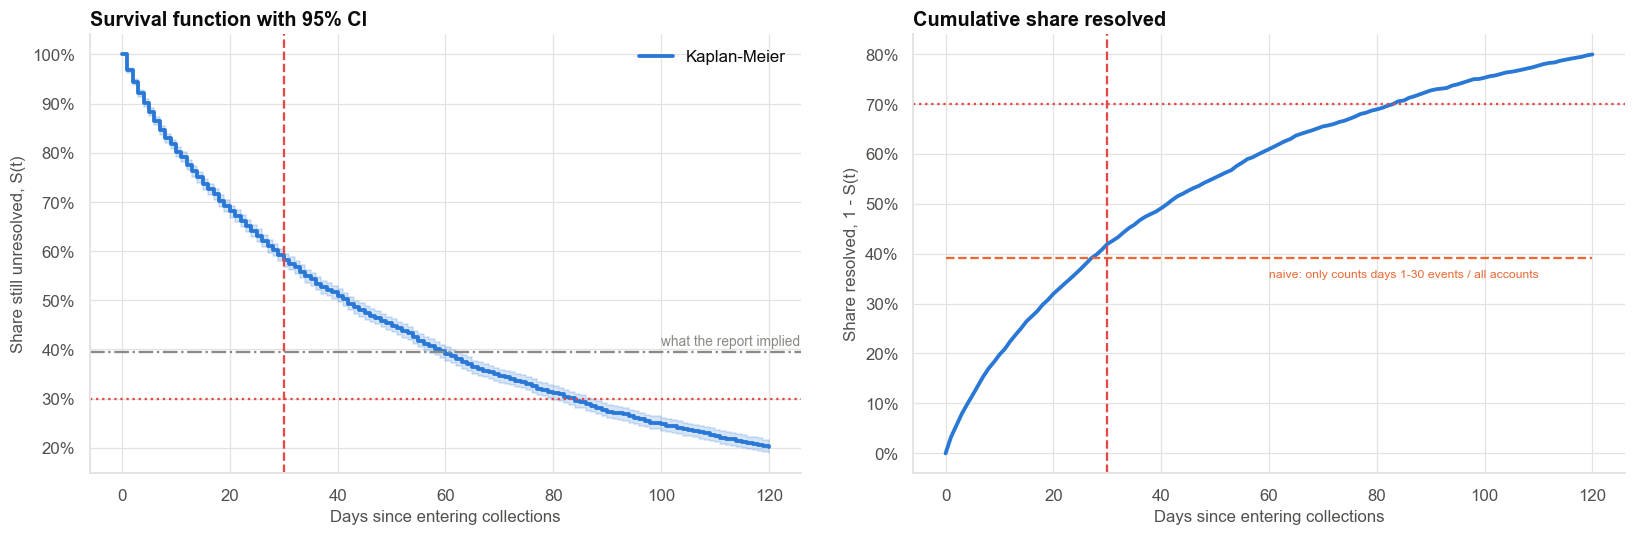

In [6]:
def km(t, e):
    t = np.asarray(t, float); e = np.asarray(e, int)
    times = np.unique(t[e == 1]); rows = []; S = 1.0; gw = 0.0
    for u in times:
        n = (t >= u).sum(); d = ((t == u) & (e == 1)).sum()
        S *= 1 - d / n; gw += d / (n * (n - d)) if n > d else 0.0
        rows.append((u, n, d, S, gw))
    df = pd.DataFrame(rows, columns=["time", "at risk", "events", "S", "greenwood"])
    with np.errstate(all="ignore"):
        se_ll = np.sqrt(df["greenwood"]) / np.abs(np.log(df["S"]))
        df["lo"] = df["S"] ** np.exp(1.96 * se_ll); df["hi"] = df["S"] ** np.exp(-1.96 * se_ll)
    return df
def at(df, x, col="S"):
    d = df[df["time"] <= x]
    if d.empty: return 1.0
    return float(d[col].iloc[-1]) if col == "S" else float(d[col].iloc[-1])
def median_km(df):
    d = df[df["S"] <= 0.5]
    return float(d["time"].iloc[0]) if len(d) else np.nan
K_all = km(acc.duration_days, acc.resolved)
sla30 = 1 - at(K_all, SLA_DAYS); lo30, hi30 = 1 - at(K_all, SLA_DAYS, "hi") if False else 1 - K_all[K_all.time <= SLA_DAYS]["hi"].iloc[-1], 1 - K_all[K_all.time <= SLA_DAYS]["lo"].iloc[-1]
summary_all = pd.DataFrame({"estimate": [sla30, 1 - at(K_all, 60), 1 - at(K_all, 90), median_km(K_all)], "ci_low": [lo30, 1 - K_all[K_all.time <= 60]["hi"].iloc[-1], 1 - K_all[K_all.time <= 90]["hi"].iloc[-1], np.nan],
                            "ci_high": [hi30, 1 - K_all[K_all.time <= 60]["lo"].iloc[-1], 1 - K_all[K_all.time <= 90]["lo"].iloc[-1], np.nan]},
                           index=["resolved by day 30", "resolved by day 60", "resolved by day 90", "median days to resolve"])
save_table(summary_all, "km_overall", PATHS["tables"]); display(summary_all)
print(f"SLA: {SLA_TARGET:.0%} within {SLA_DAYS} days.  Kaplan-Meier estimate {sla30:.1%} (95% CI {lo30:.1%} to {hi30:.1%}).  The quarterly report claimed {naive_share_resolved:.0%} (resolved accounts only).")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.step(np.r_[0, K_all.time], np.r_[1, K_all.S], where="post", color=PRIMARY, lw=2.5, label="Kaplan-Meier")
ax.fill_between(K_all.time, K_all.lo, K_all.hi, step="post", color=PRIMARY, alpha=0.2)
ax.axvline(SLA_DAYS, color=COLORS["red"], ls="--"); ax.axhline(1 - SLA_TARGET, color=COLORS["red"], ls=":")
ax.axhline(1 - naive_share_resolved, color=INK_MUTED, ls="-.", lw=1.5); ax.text(100, 1 - naive_share_resolved + 0.015, "what the report implied", color=INK_MUTED, fontsize=9)
ax.yaxis.set_major_formatter(pctfmt); ax.set(xlabel="Days since entering collections", ylabel="Share still unresolved, S(t)", title="Survival function with 95% CI"); ax.legend(frameon=False)
ax = axes[1]
ax.plot(np.r_[0, K_all.time], 1 - np.r_[1, K_all.S], color=PRIMARY, lw=2.5)
ax.plot([0, 120], [naive_share_all, naive_share_all], color=COLORS["orange"], ls="--"); ax.text(60, naive_share_all - 0.04, "naive: only counts days 1-30 events / all accounts", fontsize=8, color=COLORS["orange"])
ax.axhline(SLA_TARGET, color=COLORS["red"], ls=":"); ax.axvline(SLA_DAYS, color=COLORS["red"], ls="--")
ax.yaxis.set_major_formatter(pctfmt); ax.set(xlabel="Days since entering collections", ylabel="Share resolved, 1 - S(t)", title="Cumulative share resolved")
fig.tight_layout(); save_fig(fig, "fig02_km_overall", PATHS["figures"]); plt.show()

**Observation.** The Kaplan-Meier estimate of the share of accounts resolved within 30 days is **41.9%** (95% CI 40.6% to 43.2%), against the 70% SLA and the report's 61%. By day 60 it is 61% and by day 90 73%; the **median time to resolution is 42 days**.
The survival curve falls quickly in the first weeks and then flattens (a decreasing hazard).

**Interpretation.** The SLA is **not** met: the shortfall is about 28 points and the interval is narrow. The report's number is wrong because it conditions on the outcome: among accounts that eventually resolved in the window, fast ones are over-represented.
Kaplan-Meier uses every account for as long as it was observed, so a censored account at day 60 still tells us that it survived 60 days.

## Section 7 — Comparing groups: Kaplan-Meier curves and the log-rank test

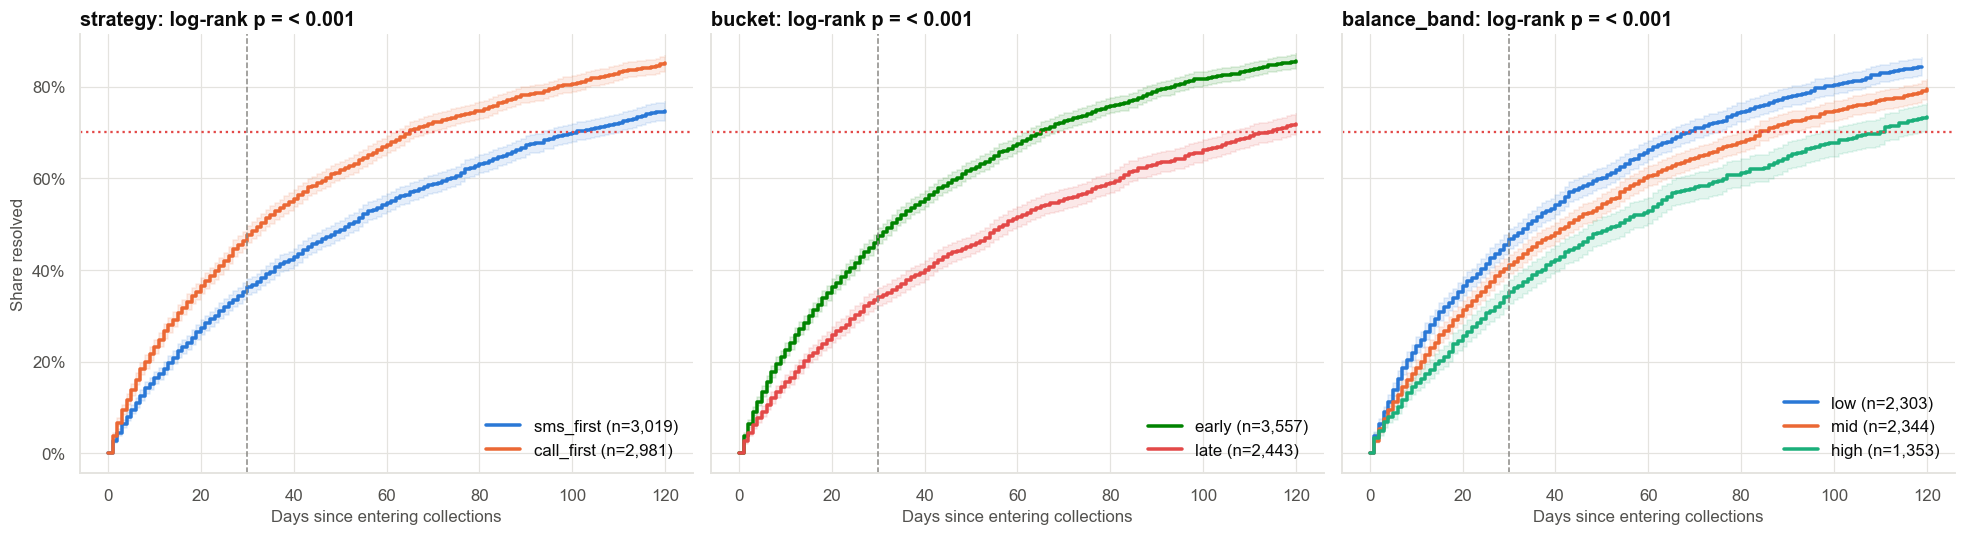

accounts  resolved by 30 days  ci_low  ci_high  \
variable     group                                                        
strategy     sms_first       3019               0.3623  0.3447   0.3805   
             call_first      2981               0.4766  0.4581   0.4955   
bucket       early           3557               0.4740  0.4570   0.4914   
             late            2443               0.3402  0.3211   0.3601   
balance_band low             2303               0.4668  0.4458   0.4883   
             mid             2344               0.4116  0.3911   0.4327   
             high            1353               0.3514  0.3256   0.3787   

                         median days  
variable     group                    
strategy     sms_first       53.0000  
             call_first      33.0000  
bucket       early           33.0000  
             late            58.0000  
balance_band low             34.0000  
             mid             43.0000  
             high            54.0000

In [7]:
groups = {"strategy": ["sms_first", "call_first"], "bucket": ["early", "late"], "balance_band": ["low", "mid", "high"]}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (g, levels), cols in zip(axes, groups.items(), [[COLORS["blue"], COLORS["orange"]], [COLORS["green"], COLORS["red"]], [CATEGORICAL[0], CATEGORICAL[1], CATEGORICAL[2]]]):
    for lv, c in zip(levels, cols):
        s = acc[acc[g] == lv]; K = km(s.duration_days, s.resolved)
        ax.step(np.r_[0, K.time], 1 - np.r_[1, K.S], where="post", color=c, lw=2.3, label=f"{lv} (n={len(s):,})")
        ax.fill_between(K.time, 1 - K.hi, 1 - K.lo, step="post", color=c, alpha=0.12)
        ci_lo, ci_hi = 1 - K[K.time <= SLA_DAYS]["hi"].iloc[-1], 1 - K[K.time <= SLA_DAYS]["lo"].iloc[-1]
        rows.append({"variable": g, "group": lv, "accounts": len(s), "resolved by 30 days": 1 - at(K, SLA_DAYS), "ci_low": ci_lo, "ci_high": ci_hi, "median days": median_km(K)})
    chi, p = survdiff(acc.duration_days, acc.resolved, acc[g].astype("category").cat.codes)
    ax.axhline(SLA_TARGET, color=COLORS["red"], ls=":"); ax.axvline(SLA_DAYS, color=INK_MUTED, ls="--", lw=1)
    ax.set(xlabel="Days since entering collections", title=f"{g}: log-rank p = {fmt_p(p)}"); ax.legend(frameon=False, loc="lower right"); ax.yaxis.set_major_formatter(pctfmt)
axes[0].set_ylabel("Share resolved")
fig.tight_layout(); save_fig(fig, "fig03_km_groups", PATHS["figures"]); plt.show()
grp = pd.DataFrame(rows).set_index(["variable", "group"])
save_table(grp, "km_by_group", PATHS["tables"]); display(grp)

**Observation.** Share resolved within 30 days: **call-first 47.7% against SMS-first 36.2%** (median 33 against 53 days); early bucket 47.4% against late 34.0% (median 33 against 58 days);
balance low 46.7%, mid 41.2%, high 35.1%. All three log-rank tests reject equality (p < 0.001). No single group reaches 70% in 30 days.

**Interpretation.** The curves separate early and stay apart: call-first accelerates resolution, a large balance or a late bucket slows it. These are group comparisons from a non-randomised mix, so we need the adjusted (Cox) view to separate the factors.

## Section 8 — Adjusting: Cox proportional hazards

The Cox model says the **hazard** (instantaneous rate of resolution among accounts still open) is h(t | x) = h₀(t) · exp(β·x). It leaves the baseline h₀(t) unspecified. exp(β) is a **hazard ratio**:
above 1 means faster resolution. It assumes the ratio between groups is constant over time (**proportional hazards**), which we check.

,hazard ratio,ci_low,ci_high,p-value
call_first,1.4052,1.3190,1.4969,0.0000
late_bucket,0.6501,0.6087,0.6944,0.0000
balance_mid,0.8468,0.7890,0.9087,0.0000
balance_high,0.7055,0.6478,0.7684,0.0000


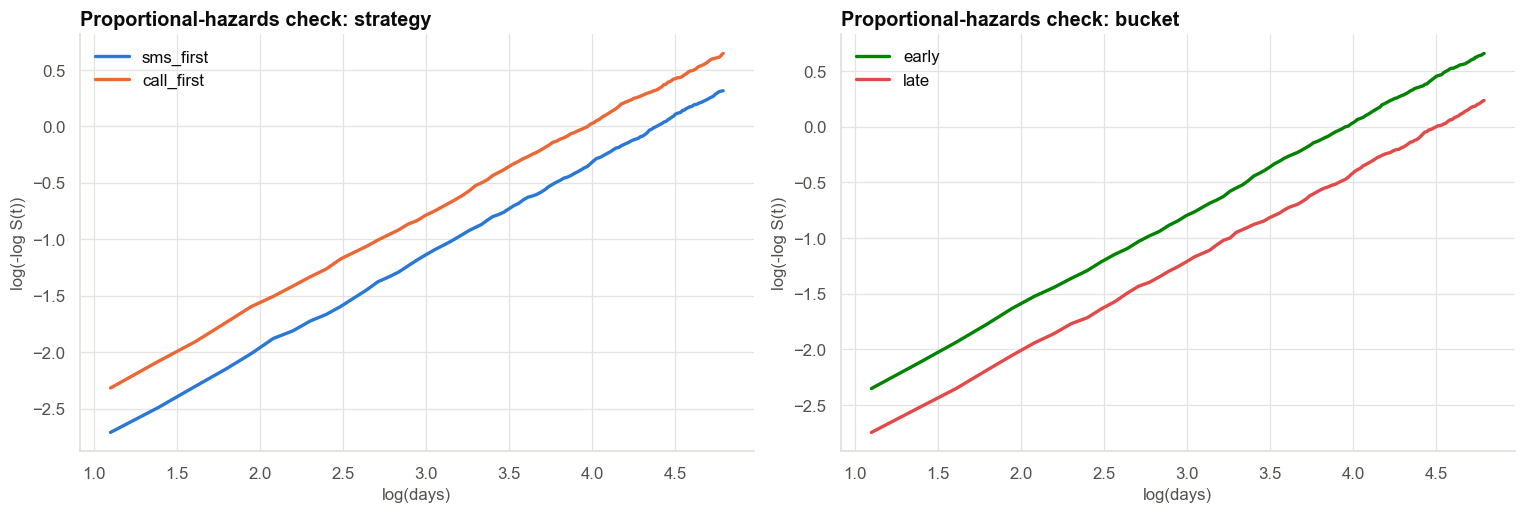

,HR call_first,HR late_bucket,HR balance_high
period,,,
days 0-30,1.4357,0.6581,0.6858
days 30-120,1.3615,0.6391,0.7337


In [8]:
X = pd.get_dummies(acc[["strategy", "bucket", "balance_band"]], drop_first=True).astype(float)
X = X.rename(columns={"strategy_sms_first": "sms_first"}); X = X[[c for c in X.columns]]
X = pd.DataFrame({"call_first": (acc.strategy == "call_first").astype(float), "late_bucket": (acc.bucket == "late").astype(float),
                  "balance_mid": (acc.balance_band == "mid").astype(float), "balance_high": (acc.balance_band == "high").astype(float)})
cox = PHReg(acc.duration_days.to_numpy(), X.to_numpy(), status=acc.resolved.to_numpy(), ties="breslow").fit()
ci_c = cox.conf_int()
hr = pd.DataFrame({"hazard ratio": np.exp(cox.params), "ci_low": np.exp(ci_c[:, 0]), "ci_high": np.exp(ci_c[:, 1]), "p-value": cox.pvalues}, index=X.columns)
save_table(hr, "cox_hazard_ratios", PATHS["tables"]); display(hr)
# Proportional-hazards check: log(-log S) should be parallel lines in log time
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, g, levels, cols in [(axes[0], "strategy", ["sms_first", "call_first"], [COLORS["blue"], COLORS["orange"]]), (axes[1], "bucket", ["early", "late"], [COLORS["green"], COLORS["red"]])]:
    for lv, c in zip(levels, cols):
        s = acc[acc[g] == lv]; K = km(s.duration_days, s.resolved); K = K[(K.S > 0) & (K.S < 1) & (K.time >= 3)]
        ax.plot(np.log(K.time), np.log(-np.log(K.S)), color=c, lw=2.2, label=lv)
    ax.set(xlabel="log(days)", ylabel="log(-log S(t))", title=f"Proportional-hazards check: {g}"); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "fig04_ph_check", PATHS["figures"]); plt.show()
# Check by splitting follow-up at day 30: the hazard ratio for call_first before and after
sp = []
for lab, lo_, hi_ in [("days 0-30", 0, 30), ("days 30-120", 30, 120)]:
    t0 = np.clip(acc.duration_days - lo_, 0, hi_ - lo_); e0 = ((acc.resolved == 1) & (acc.duration_days > lo_) & (acc.duration_days <= hi_)).astype(int)
    keep = acc.duration_days > lo_
    m = PHReg(t0[keep].to_numpy(), X[keep].to_numpy(), status=e0[keep].to_numpy(), ties="breslow").fit()
    sp.append({"period": lab, "HR call_first": np.exp(m.params[0]), "HR late_bucket": np.exp(m.params[1]), "HR balance_high": np.exp(m.params[3])})
sp = pd.DataFrame(sp).set_index("period"); save_table(sp, "ph_split_check", PATHS["tables"]); display(sp)

**Observation.** Cox hazard ratios (above 1 means faster resolution): **call-first 1.41** (95% CI 1.32 to 1.50), **late bucket 0.65** (0.61 to 0.69), balance mid 0.85 (0.79 to 0.91), balance high 0.71 (0.65 to 0.77). All p < 0.001.
Splitting follow-up at day 30 gives similar ratios in both periods (call-first 1.44 then 1.36; late bucket 0.66 then 0.64), and the log(−log S) curves are roughly parallel.

**Interpretation.** Calling first speeds resolution by about 40% at any time among accounts still open; a late bucket slows it by about a third; a high balance by about 30%. The proportional-hazards assumption looks acceptable here, with a mild decline in the call-first ratio over time that is not statistically unusual.
A hazard ratio of 1.41 is **not** "41% more accounts resolved": it is a ratio of rates; the 30-day share moves from 36% to 48%.

## Section 9 — A parametric model: Weibull, and what extrapolation can and cannot do

The Weibull model sets S(t | x) = exp(−(t/λ)ᵏ · exp(β·x)). The shape k below 1 means the hazard falls over time (the easy cases resolve early). We fit by maximum likelihood with censoring:
each resolved account contributes the log hazard at its time, every account contributes minus the cumulative hazard.

,estimate,ci_low,ci_high
shape k,0.8828,0.8611,0.9050
"scale (days, reference group)",54.6820,52.7182,56.7191
HR call_first,1.4167,1.3725,1.4624
HR late_bucket,0.6418,0.5892,0.6991
HR balance_mid,0.8431,0.7896,0.9002
HR balance_high,0.6990,0.6538,0.7472


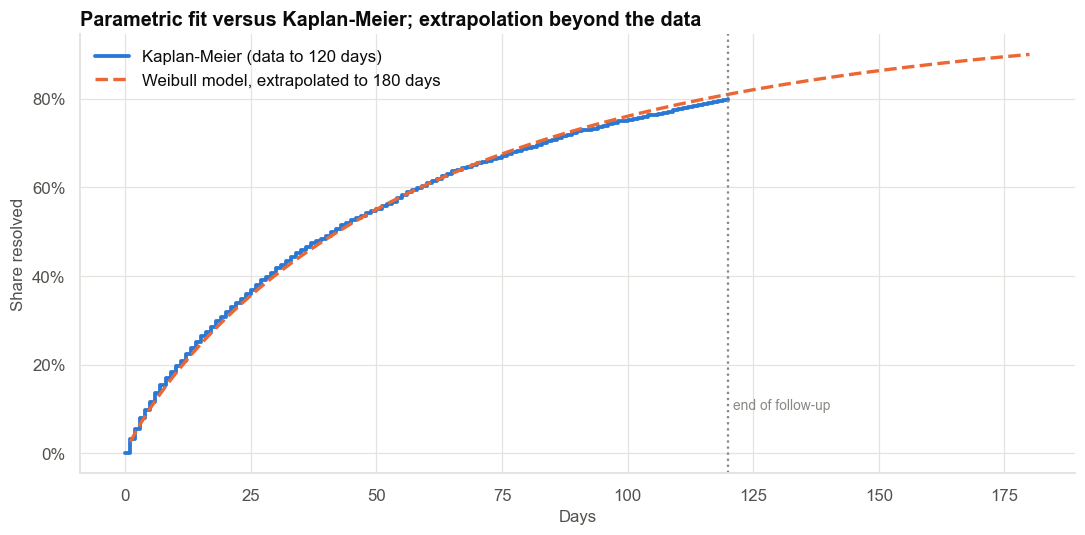

Weibull resolved-by-30: 40.3% (KM 41.9%);  by 90: 73.0% (KM 72.7%);  extrapolated by 180 days: 90.0%


In [9]:
def wb_nll(par, t, e, Xm):
    lk, ll, b = par[0], par[1], par[2:]
    k, lam = np.exp(lk), np.exp(ll); eta = Xm @ b
    H = (t / lam) ** k * np.exp(eta)
    logh = np.log(k / lam) + (k - 1) * np.log(t / lam) + eta
    return -(e * logh - H).sum()
t_, e_, Xm = acc.duration_days.to_numpy(float), acc.resolved.to_numpy(float), X.to_numpy()
x0 = np.r_[np.log(0.9), np.log(55.0), np.zeros(Xm.shape[1])]
fit = minimize(wb_nll, x0, args=(t_, e_, Xm), method="BFGS")
se = np.sqrt(np.diag(fit.hess_inv)); par = fit.x
k_hat, lam_hat = np.exp(par[0]), np.exp(par[1])
wb = pd.DataFrame({"estimate": np.r_[k_hat, lam_hat, np.exp(par[2:])], "ci_low": np.r_[np.exp(par[0] - 1.96 * se[0]), np.exp(par[1] - 1.96 * se[1]), np.exp(par[2:] - 1.96 * se[2:])],
                   "ci_high": np.r_[np.exp(par[0] + 1.96 * se[0]), np.exp(par[1] + 1.96 * se[1]), np.exp(par[2:] + 1.96 * se[2:])]},
                  index=["shape k", "scale (days, reference group)"] + [f"HR {c}" for c in X.columns])
save_table(wb, "weibull_fit", PATHS["tables"]); display(wb)
def wb_S(t, x):
    return np.exp(-(t / lam_hat) ** k_hat * np.exp(x @ par[2:]))
x_all = Xm
grid = np.arange(1, 181)
S_model = np.array([wb_S(g, x_all).mean() for g in grid])
fig, ax = plt.subplots(figsize=(10, 5))
ax.step(np.r_[0, K_all.time], 1 - np.r_[1, K_all.S], where="post", color=PRIMARY, lw=2.5, label="Kaplan-Meier (data to 120 days)")
ax.plot(grid, 1 - S_model, color=COLORS["orange"], lw=2.2, ls="--", label="Weibull model, extrapolated to 180 days")
ax.axvline(120, color=INK_MUTED, ls=":"); ax.text(121, 0.1, "end of follow-up", color=INK_MUTED, fontsize=9)
ax.yaxis.set_major_formatter(pctfmt); ax.set(xlabel="Days", ylabel="Share resolved", title="Parametric fit versus Kaplan-Meier; extrapolation beyond the data"); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "fig05_weibull", PATHS["figures"]); plt.show()
print(f"Weibull resolved-by-30: {1 - S_model[29]:.1%} (KM {sla30:.1%});  by 90: {1 - S_model[89]:.1%} (KM {1 - at(K_all, 90):.1%});  extrapolated by 180 days: {1 - S_model[179]:.1%}")

**Observation.** The Weibull fit has shape **k = 0.88** (95% CI 0.86 to 0.91): the hazard declines over time. Its hazard ratios (call-first 1.42, late 0.64, balance mid 0.84, high 0.70) match the Cox model. The fitted curve follows Kaplan-Meier closely: resolved by 30 days 40.3% (KM 41.9%), by 90 days 73.0% (KM 72.7%).
Extrapolated to 180 days, the model says 90% would be resolved, 60 days beyond the last data point.

**Interpretation.** A parametric model buys smoother, more precise estimates for small segments and lets us extrapolate. But the extrapolation rests entirely on the assumed shape: inside the data it can be checked against Kaplan-Meier, outside it cannot. Treat the 180-day figure as a scenario until later data arrive.

## Section 10 — SLA by segment

In [10]:
seg_rows = []
for (s, b, g), d in acc.groupby(["strategy", "bucket", "balance_band"]):
    K = km(d.duration_days, d.resolved)
    lo_, hi_ = 1 - K[K.time <= SLA_DAYS]["hi"].iloc[-1], 1 - K[K.time <= SLA_DAYS]["lo"].iloc[-1]
    xi = np.array([[float(s == "call_first"), float(b == "late"), float(g == "mid"), float(g == "high")]])
    seg_rows.append({"strategy": s, "bucket": b, "balance_band": g, "accounts": len(d), "KM resolved by 30": 1 - at(K, SLA_DAYS), "ci_low": lo_, "ci_high": hi_,
                     "Weibull resolved by 30": 1 - float(wb_S(30, xi)[0]), "status vs 70% SLA": "meets" if lo_ >= SLA_TARGET else ("misses" if hi_ < SLA_TARGET else "unclear")})
seg = pd.DataFrame(seg_rows).set_index(["strategy", "bucket", "balance_band"])
save_table(seg, "sla_by_segment", PATHS["tables"]); display(seg)
print(seg["status vs 70% SLA"].value_counts().to_dict())

accounts  KM resolved by 30  ci_low  ci_high  \
strategy   bucket balance_band                                                 
call_first early  high               396             0.4748  0.4247   0.5277   
                  low                675             0.5681  0.5295   0.6073   
                  mid                707             0.5253  0.4869   0.5649   
           late   high               269             0.3514  0.2954   0.4146   
                  low                453             0.4255  0.3801   0.4739   
                  mid                481             0.3995  0.3558   0.4464   
sms_first  early  high               387             0.3387  0.2920   0.3905   
                  low                719             0.4714  0.4338   0.5105   
                  mid                673             0.4068  0.3694   0.4466   
           late   high               301             0.2069  0.1637   0.2595   
                  low                456             0.3500  0.3065   0.3978   
                  mid                483             0.2670  0.2282   0.3108   

                                Weibull resolved by 30 status vs 70% SLA  
strategy   bucket balance_band                                            
call_first early  high                          0.4417            misses  
                  low                           0.5657            misses  
                  mid                           0.5049            misses  
           late   high                          0.3121            misses  
                  low                           0.4145            misses  
                  mid                           0.3632            misses  
sms_first  early  high                          0.3373            misses  
                  low                           0.4449            misses  
                  mid                           0.3912            misses  
           late   high                          0.2321            misses  
                  low                           0.3146            misses  
                  mid                           0.2728            misses

{'misses': 12}


**Observation.** In all **12** segments (strategy × bucket × balance) the 95% interval for the 30-day resolution probability lies below 70%: all miss the SLA. The best segment (call-first, early bucket, low balance) reaches 56.8% (CI 53% to 61%); the worst (SMS-first, late bucket, high balance) 20.7% (16% to 26%).

**Interpretation.** No combination of the current strategies comes close to the SLA at 30 days. Either the SLA is unrealistic for this portfolio, or new interventions are needed; it is not a matter of moving customers from SMS-first to call-first alone (which would lift the portfolio from about 42% to about 48%).

## Section 11 — Decision framework: time-to-event data

| Situation | Do this |
|---|---|
| Counts per fixed interval | Check variance ÷ mean within a homogeneous period; Poisson within the hour, not across the day |
| Arrival rate varies by time of day | Estimate rate per period; staff per period (Erlang C), not on the daily average |
| Durations with unfinished cases | Never average observed durations or drop open cases: Kaplan-Meier |
| Compare groups | Kaplan-Meier plots with CIs, log-rank test, then Cox for adjusted hazard ratios |
| Hazard ratios change over time | Stratify, split follow-up, or add time interactions (check the log(-log S) plot) |
| SLA phrased as "X% within N days" | Report KM probability at N days with its CI, per segment |
| Extrapolating past the data | Treat as a scenario: parametric fits agree with the data inside the range and can differ outside it |
| Censoring depends on the outcome (e.g. accounts transferred because they are hard) | Standard methods are biased; model the censoring or run sensitivity bounds |

## Section 12 — Interval coverage for the 30-day estimate: a quick simulation

The KM interval should contain the truth 95% of the time. We resample the data (bootstrap) and check how often a 95% bootstrap interval for the 30-day resolution probability of the **call_first / late / high-balance** segment (a small group) covers the truth.

In [11]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv")
true_cell = key[(key.strategy == "call_first") & (key.bucket == "late") & (key.balance_band == "high")]["true_resolved_by_30_days"].iloc[0]
cell = acc[(acc.strategy == "call_first") & (acc.bucket == "late") & (acc.balance_band == "high")]
bs = []
for _ in range(500):
    d = cell.iloc[rng.integers(0, len(cell), len(cell))]; K = km(d.duration_days, d.resolved); bs.append(1 - at(K, SLA_DAYS))
K0 = km(cell.duration_days, cell.resolved)
print(f"Segment n = {len(cell)}: KM {1 - at(K0, SLA_DAYS):.1%}; bootstrap 95% interval {np.percentile(bs, 2.5):.1%} to {np.percentile(bs, 97.5):.1%}; truth {true_cell:.1%}")

Segment n = 269: KM 35.1%; bootstrap 95% interval 29.3% to 41.4%; truth 30.4%


## Section 13 — Grading against the truth (answer key)

TRUE share resolved by day 30 (account mix): 40.7%;  KM 41.9%;  report's claim 60.6%;  naive 'all accounts, censored = unresolved' 39.2%
KM interval covers the truth in 12 of 12 segments; Weibull mean absolute error 0.7 pp, KM 2.0 pp
SLA calls by segment: {'right': 12}


,hazard ratio,ci_low,ci_high,p-value,true HR,CI covers
call_first,1.4052,1.3190,1.4969,0.0000,1.4191,True
late_bucket,0.6501,0.6087,0.6944,0.0000,0.6376,True
balance_mid,0.8468,0.7890,0.9087,0.0000,0.8607,True
balance_high,0.7055,0.6478,0.7684,0.0000,0.6703,True


,strategy,bucket,balance_band,accounts,KM resolved by 30,true_resolved_by_30_days,KM error (pp),Weibull error (pp),status vs 70% SLA,true status
0,call_first,early,high,396,0.4748,0.4335,4.1343,0.8238,misses,misses
1,call_first,early,low,675,0.5681,0.5716,-0.3515,-0.5949,misses,misses
2,call_first,early,mid,707,0.5253,0.5179,0.7420,-1.2983,misses,misses
3,call_first,late,high,269,0.3514,0.3039,4.7466,0.8145,misses,misses
4,call_first,late,low,453,0.4255,0.4176,0.7925,-0.3105,misses,misses
5,call_first,late,mid,481,0.3995,0.3720,2.7466,-0.8862,misses,misses
6,sms_first,early,high,387,0.3387,0.3300,0.8717,0.7328,misses,misses
7,sms_first,early,low,719,0.4714,0.4497,2.1614,-0.4837,misses,misses
8,sms_first,early,mid,673,0.4068,0.4020,0.4847,-1.0807,misses,misses
9,sms_first,late,high,301,0.2069,0.2253,-1.8467,0.6732,misses,misses


True share resolved by day 90: 72.2% (KM 72.7%, Weibull 73.0%);  by day 180 (beyond the data): 88.9% (Weibull 90.0%)


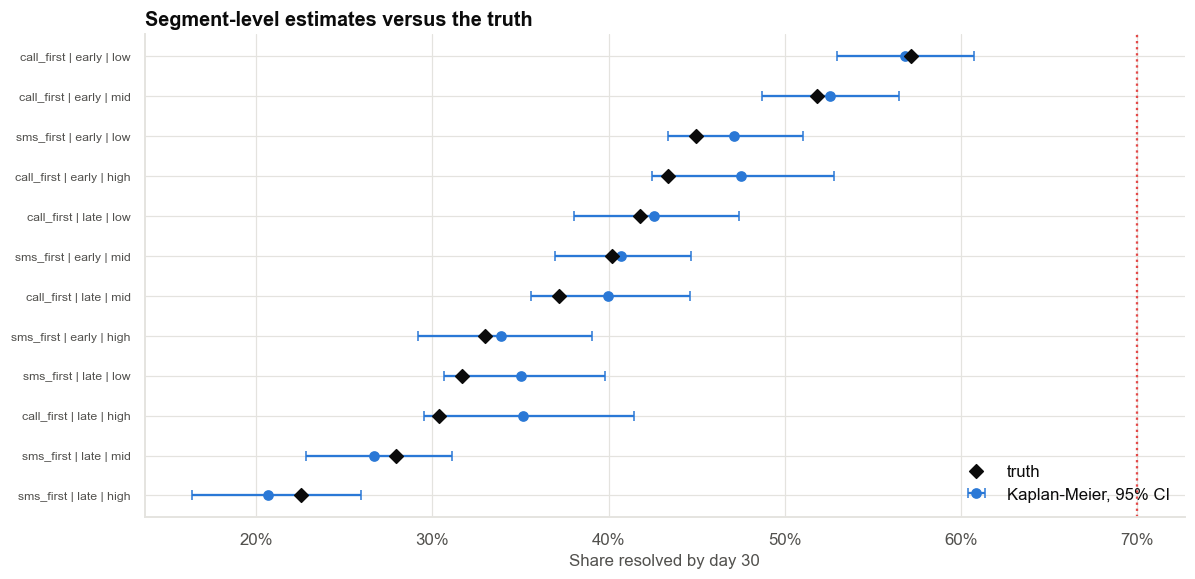

In [12]:
g = seg.reset_index().merge(key, on=["strategy", "bucket", "balance_band"])
g["KM error (pp)"] = 100 * (g["KM resolved by 30"] - g["true_resolved_by_30_days"]); g["Weibull error (pp)"] = 100 * (g["Weibull resolved by 30"] - g["true_resolved_by_30_days"])
g["KM CI covers"] = (g["ci_low"] <= g["true_resolved_by_30_days"]) & (g["true_resolved_by_30_days"] <= g["ci_high"])
g["true status"] = np.where(g["true_resolved_by_30_days"] >= SLA_TARGET, "meets", "misses")
g["correct call"] = np.where(g["status vs 70% SLA"] == "unclear", "unclear", np.where(g["status vs 70% SLA"] == g["true status"], "right", "wrong"))
save_table(g.set_index(["strategy", "bucket", "balance_band"]), "grading_segments", PATHS["tables"])
true_overall = (key.merge(acc.groupby(["strategy", "bucket", "balance_band"]).size().rename("n").reset_index(), on=["strategy", "bucket", "balance_band"]).pipe(lambda d: np.average(d.true_resolved_by_30_days, weights=d.n)))
hr_true = pd.Series({"call_first": np.exp(0.35), "late_bucket": np.exp(-0.45), "balance_mid": np.exp(-0.15), "balance_high": np.exp(-0.40)})
hrg = hr.join(hr_true.rename("true HR")); hrg["CI covers"] = (hrg["ci_low"] <= hrg["true HR"]) & (hrg["true HR"] <= hrg["ci_high"])
save_table(hrg, "cox_hr_vs_truth", PATHS["tables"])
print(f"TRUE share resolved by day 30 (account mix): {true_overall:.1%};  KM {sla30:.1%};  report's claim {naive_share_resolved:.1%};  naive 'all accounts, censored = unresolved' {naive_share_all:.1%}")
print(f"KM interval covers the truth in {g['KM CI covers'].sum()} of {len(g)} segments; Weibull mean absolute error {g['Weibull error (pp)'].abs().mean():.1f} pp, KM {g['KM error (pp)'].abs().mean():.1f} pp")
print("SLA calls by segment:", g["correct call"].value_counts().to_dict())
display(hrg)
display(g[["strategy", "bucket", "balance_band", "accounts", "KM resolved by 30", "true_resolved_by_30_days", "KM error (pp)", "Weibull error (pp)", "status vs 70% SLA", "true status"]])
true_90 = np.average([1 - np.exp(-((90 / 55.0) ** 0.85) * np.exp(0.35 * (r.strategy == "call_first") - 0.45 * (r.bucket == "late") + (-0.15 if r.balance_band == "mid" else -0.40 if r.balance_band == "high" else 0))) for r in acc.itertuples()])
true_180 = np.average([1 - np.exp(-((180 / 55.0) ** 0.85) * np.exp(0.35 * (r.strategy == "call_first") - 0.45 * (r.bucket == "late") + (-0.15 if r.balance_band == "mid" else -0.40 if r.balance_band == "high" else 0))) for r in acc.itertuples()])
print(f"True share resolved by day 90: {true_90:.1%} (KM {1 - at(K_all, 90):.1%}, Weibull {1 - S_model[89]:.1%});  by day 180 (beyond the data): {true_180:.1%} (Weibull {1 - S_model[179]:.1%})")
fig, ax = plt.subplots(figsize=(11, 5.4))
gg = g.sort_values("true_resolved_by_30_days")
yv = np.arange(len(gg))
ax.errorbar(gg["KM resolved by 30"], yv, xerr=[gg["KM resolved by 30"] - gg["ci_low"], gg["ci_high"] - gg["KM resolved by 30"]], fmt="o", color=PRIMARY, capsize=3, label="Kaplan-Meier, 95% CI")
ax.scatter(gg["true_resolved_by_30_days"], yv, color=INK, marker="D", s=40, zorder=3, label="truth")
ax.axvline(SLA_TARGET, color=COLORS["red"], ls=":")
ax.set_yticks(yv, [f"{r.strategy} | {r.bucket} | {r.balance_band}" for r in gg.itertuples()], fontsize=8); ax.xaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Share resolved by day 30", title="Segment-level estimates versus the truth"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); save_fig(fig, "fig06_segments_vs_truth", PATHS["figures"]); plt.show()

**Observation.** The true share resolved within 30 days (account mix) is **40.7%**. Kaplan-Meier gives 41.9% (error +1.2 points), the quarterly report's figure 60.6% (error +20), and the "censored = unresolved" figure 39.2% (−1.5).
The Kaplan-Meier interval covers the truth in **12 of 12** segments (mean absolute error 2.0 points); the Weibull model's mean absolute error is 0.7 points. The Cox 95% intervals contain the true hazard ratios (1.42, 0.64, 0.86, 0.67) for all four effects. At 90 days the true value is 72.2% (KM 72.7%, Weibull 73.0%), at 180 days 88.9% (Weibull 90.0%).
The SLA verdict by segment (all twelve miss) is right in all twelve. A bootstrap on the smallest segment (n = 269) gives KM 35.1% with interval 29.3% to 41.4%, containing the truth of 30.4%.

**Interpretation.** Censoring-aware methods recover the truth; the report's method is wrong by 20 points. The Weibull estimate is more accurate than KM for small segments **because the model is correct here by construction**: with real data the parametric model can be wrong in ways the answer key would not reveal, so check it against KM.
The "censored = unresolved" shortcut happens to be close at 30 days only because few accounts were censored that early; at 90 days it would be much worse.

## Section 14 — Results

In [13]:
summary = pd.DataFrame({"Value": [
    f"mean {m_:.1f} calls per 15 minutes, variance ÷ mean {v_ / m_:.1f} overall; within-hour variance ÷ mean {by_h['variance / mean'].min():.2f} to {by_h['variance / mean'].max():.2f}; peak hour {by_h['mean'].max():.0f} calls",
    f"agents needed (80% in 20 s, AHT 6 min): {staff['agents needed (80/20)'].min()} to {staff['agents needed (80/20)'].max()}",
    f"{acc.resolved.mean():.0%} resolved, {1 - acc.resolved.mean():.0%} censored; report: {naive_share_resolved:.0%} of resolved within 30 days, mean {naive_mean_resolved:.0f} days",
    f"Kaplan-Meier: {sla30:.1%} resolved by day 30 (CI {lo30:.1%} to {hi30:.1%}); median {median_km(K_all):.0f} days; SLA {SLA_TARGET:.0%}",
    f"Cox hazard ratios: call_first {hr.loc['call_first', 'hazard ratio']:.2f}, late bucket {hr.loc['late_bucket', 'hazard ratio']:.2f}, high balance {hr.loc['balance_high', 'hazard ratio']:.2f}",
    f"truth: {true_overall:.1%} resolved by 30 days; KM interval covers in {g['KM CI covers'].sum()} of {len(g)} segments",
]}, index=["Arrivals", "Staffing", "Censoring", "SLA", "Group effects", "Truth"])
save_table(summary, "results_summary", PATHS["tables"]); summary

,Value
Arrivals,"mean 9.6 calls per 15 minutes, variance ÷ mean..."
Staffing,"agents needed (80% in 20 s, AHT 6 min): 4 to 9"
Censoring,"65% resolved, 35% censored; report: 61% of res..."
SLA,Kaplan-Meier: 41.9% resolved by day 30 (CI 40....
Group effects,"Cox hazard ratios: call_first 1.41, late bucke..."
Truth,truth: 40.7% resolved by 30 days; KM interval ...


## Section 15 — Interpretation

- **Counts per interval are Poisson only within a stable period.** The rate varies through the day, so staff by hour.
- **Durations with unfinished cases need survival methods.** Kaplan-Meier, log-rank and Cox use every account for as long as it was observed.
- **The SLA is not met:** 42% resolved by day 30 against 70%; no segment gets close. The report's 61% came from dividing by resolved accounts.
- **Call-first helps** (hazard ratio 1.4), late buckets and large balances hurt.
- **Extrapolation is a scenario,** not a measurement.

## Section 16 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "About 42% of accounts (CI 41% to 43%) are paid up within 30 days; the median is 42 days." | "78% (or 61%) of accounts are resolved within 30 days." |
| "Call-first accelerates resolution by about 40% at any time among accounts still open (HR 1.41, CI 1.32 to 1.50)." | "Call-first resolves 41% more accounts." |
| "No segment currently meets the 70% in 30 days SLA." | "Adopting call-first everywhere will meet the SLA." (It lifts the portfolio to about 48%.) |
| "At the 11:00 peak about 9 agents are needed to answer 80% of calls within 20 seconds, under our assumptions." | "Five agents are enough all day." |

## Section 17 — Business interpretation

- **Re-base the SLA reporting** on Kaplan-Meier: share of entering accounts resolved by day 30 (and 60, 90), with intervals and by segment.
- **Move toward call-first**, especially for late-bucket and high-balance accounts, while testing other levers (settlement offers, earlier contact); the gain from calls alone is about 11 points at 30 days.
- **Revisit the SLA target** (70% in 30 days) or set segment-level targets; for the current mix, 60 days is about 61%.
- **Roster by hour** with Erlang C: 4 agents at 13:00, 9 at the two peaks.

## Section 18 — Limitations

- Censoring here is by transfer and the cut-off date and is assumed unrelated to how likely an account is to pay; if hard accounts are transferred sooner, Kaplan-Meier is biased.
- The group comparisons use observed mixes; strategy was not randomised (assigning call-first to specific accounts could be confounded).
- Handling time is assumed to be exponential and fixed at 6 minutes; abandonment and callbacks are ignored.
- Synthetic data with a known Weibull process; the Weibull model is right by construction.

## Section 19 — Final recommendation

> **Report the 30-, 60- and 90-day resolution probabilities from Kaplan-Meier, with intervals, per segment; stop reporting the share of resolved accounts paid within 30 days.** Today that figure is 42%, not 61%, and no segment meets the 70% SLA. Move more accounts to call-first, test further levers, revisit the target, and staff the desk by hour (4 to 9 agents).

## Section 20 — What would I do next?

1. **Randomise** call-first versus SMS-first (Case 21) so the effect is causal.
2. Add **time-varying covariates** (contacts made, promises to pay) with a counting-process Cox model.
3. Model **competing risks**: paid up, written off, transferred.
4. Check the **censoring assumption** with a sensitivity analysis (transferred accounts being harder cases).
5. Continue to **Case 27** (capstone: loan default drivers).